## **What is the probability of pulling a card that is green and reverse in a 7-card Uno hand?**

I will simulate one hand from an Uno deck, which is **simple random sampling**. 
One trial includes 7 cards, and the outcomes consist of number, action, and wild cards, ranging from the colors red, blue, green, and yellow. 
I will measure **joint probability**, which is represented by drawing a green (A) reverse card (B).
Events A and B are **not mutually exclusive** because a card can be both green and reverse.
Events A and B are **not independant** because $P(\text{Green} \cap \text{Reverse}) \neq P(\text{Green}) \cdot P(\text{Reverse})$.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

num_trials = 100_000
hand_size = 7

In [30]:
draws = np.random.hypergeometric(ngood=2, nbad=106, nsample=hand_size, size=num_trials)

In [31]:
df = pd.DataFrame({'green_reverses_drawn': draws})

In [32]:
df['success'] = df['green_reverses_drawn'] > 0
df['cumulative_successes'] = df['success'].cumsum()
df['relative_frequency'] = df['success'].expanding().mean()

In [33]:
empirical_prob = df['success'].mean()
theoretical_prob = 1 - (math.comb(106, 7) / math.comb(108, 7))

In [34]:
print(f"Empirical Probability:   {empirical_prob:.4f}")
print(f"Theoretical Probability: {theoretical_prob:.4f}")

Empirical Probability:   0.1264
Theoretical Probability: 0.1260


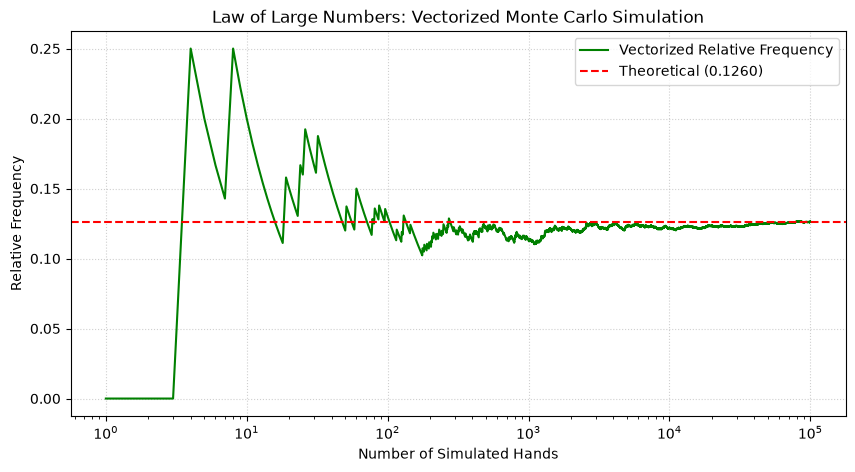

In [38]:
plt.figure(figsize=(10, 5))
plt.plot(df.index + 1, df['relative_frequency'], color='green', label='Vectorized Relative Frequency')
plt.axhline(y=theoretical_prob, color='red', linestyle='--', label=f'Theoretical ({theoretical_prob:.4f})')
plt.title('Law of Large Numbers: Vectorized Monte Carlo Simulation')
plt.xlabel('Number of Simulated Hands')
plt.ylabel('Relative Frequency')
plt.xscale('log')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

The close-knitting of my empirical probability to my theoretical probability supports my results by showing mathematical allignment to my simulation resuls.

Pulling a card that is green and reverse in a standard 7-card hand has a 12.60% theoretical probability and 12.64% empirical probability. This means that for every 8 hands, on average, there will be atleast one green reverse card.